# 04: Predict celltypes

In [191]:
import spatialdata as sd
import spatialdata_plot
import seaborn as sns
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from xgboost import XGBClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
from sklearn.preprocessing import LabelEncoder
import scanpy as sc
import scanpy.external as sce
import anndata as ad
import pandas as pd

In [192]:
proj_dir = Path("/lustre/groups/ml01/projects/2025_ttreis_icml_cpmeasure")
data_dir = proj_dir / Path("data")
halfbrain_path = data_dir / Path("halfbrain_sdata_celltypes.zarr")
quarterbrain_path = data_dir / Path("quarterbrain_sdata_celltypes.zarr")

In [193]:
sdata_quarter = sd.read_zarr(quarterbrain_path)
sdata_half = sd.read_zarr(halfbrain_path)

version mismatch: detected: RasterFormatV02, requested: FormatV04


/ictstr01/home/icb/tim.treis/miniconda/envs/cpmeasure_icml/lib/python3.11/site-packages/zarr/creation.py:610: UserWarning: ignoring keyword argument 'read_only'
  compressor, fill_value = _kwargs_compat(compressor, fill_value, kwargs)
/ictstr01/home/icb/tim.treis/miniconda/envs/cpmeasure_icml/lib/python3.11/site-packages/zarr/creation.py:610: UserWarning: ignoring keyword argument 'read_only'
  compressor, fill_value = _kwargs_compat(compressor, fill_value, kwargs)
/ictstr01/home/icb/tim.treis/miniconda/envs/cpmeasure_icml/lib/python3.11/site-packages/zarr/creation.py:610: UserWarning: ignoring keyword argument 'read_only'
  compressor, fill_value = _kwargs_compat(compressor, fill_value, kwargs)
/ictstr01/home/icb/tim.treis/miniconda/envs/cpmeasure_icml/lib/python3.11/site-packages/zarr/creation.py:610: UserWarning: ignoring keyword argument 'read_only'
  compressor, fill_value = _kwargs_compat(compressor, fill_value, kwargs)
/ictstr01/home/icb/tim.treis/miniconda/envs/cpmeasure_icml/l

In [194]:
sdata_quarter

SpatialData object, with associated Zarr store: /ictstr01/groups/ml01/projects/2025_ttreis_icml_cpmeasure/data/quarterbrain_sdata_celltypes.zarr
├── Images
│     └── 'stitched_image': DataTree[cyx] (5, 25589, 46923), (5, 12794, 23461), (5, 6397, 11730), (5, 3198, 5865), (5, 1599, 2932)
├── Labels
│     └── 'segmentation': DataTree[yx] (25589, 46923), (12794, 23461), (6397, 11730), (3198, 5865), (1599, 2932)
├── Points
│     └── 'points': DataFrame with shape: (<Delayed>, 12) (3D points)
└── Tables
      └── 'gexp': AnnData (38996, 960)
with coordinate systems:
    ▸ 'global', with elements:
        stitched_image (Images), segmentation (Labels), points (Points)

In [195]:
sdata_half

SpatialData object, with associated Zarr store: /ictstr01/groups/ml01/projects/2025_ttreis_icml_cpmeasure/data/halfbrain_sdata_celltypes.zarr
├── Images
│     └── 'stitched_image': DataTree[cyx] (5, 59881, 46914), (5, 29940, 23457), (5, 14970, 11728), (5, 7485, 5864), (5, 3742, 2932)
├── Labels
│     └── 'segmentation': DataTree[yx] (59881, 46914), (29940, 23457), (14970, 11728), (7485, 5864), (3742, 2932)
├── Points
│     └── 'points': DataFrame with shape: (<Delayed>, 12) (3D points)
└── Tables
      └── 'gexp': AnnData (48556, 960)
with coordinate systems:
    ▸ 'global', with elements:
        stitched_image (Images), segmentation (Labels), points (Points)

## gexp QC

In [196]:
sdata_quarter.tables["gexp"].var["mt"] = sdata_quarter.tables["gexp"].var_names.str.startswith("MT-")
sdata_quarter.tables["gexp"].var["ribo"] = sdata_quarter.tables["gexp"].var_names.str.startswith(("RPS", "RPL"))
sdata_quarter.tables["gexp"].var["hb"] = sdata_quarter.tables["gexp"].var_names.str.contains("^HB[^(P)]")

sdata_half.tables["gexp"].var["mt"] = sdata_half.tables["gexp"].var_names.str.startswith("MT-")
sdata_half.tables["gexp"].var["ribo"] = sdata_half.tables["gexp"].var_names.str.startswith(("RPS", "RPL"))
sdata_half.tables["gexp"].var["hb"] = sdata_half.tables["gexp"].var_names.str.contains("^HB[^(P)]")

In [197]:
sc.pp.calculate_qc_metrics(
    sdata_quarter.tables["gexp"],
    qc_vars=["mt", "ribo", "hb"],
    inplace=True,
    log1p=True,
)

sc.pp.calculate_qc_metrics(
    sdata_half.tables["gexp"],
    qc_vars=["mt", "ribo", "hb"],
    inplace=True,
    log1p=True,
)

/ictstr01/home/icb/tim.treis/miniconda/envs/cpmeasure_icml/lib/python3.11/site-packages/scanpy/preprocessing/_qc.py:432: RuntimeWarning: invalid value encountered in divide
  return values / sums[:, None]
/ictstr01/home/icb/tim.treis/miniconda/envs/cpmeasure_icml/lib/python3.11/site-packages/scanpy/preprocessing/_qc.py:432: RuntimeWarning: invalid value encountered in divide
  return values / sums[:, None]


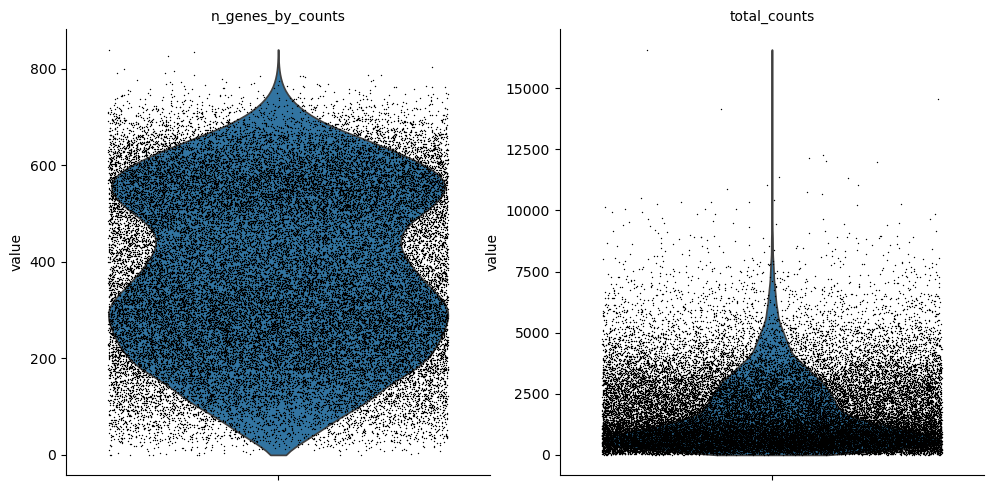

In [198]:
sc.pl.violin(
    sdata_quarter.tables["gexp"],
    ["n_genes_by_counts", "total_counts"],
    jitter=0.4,
    multi_panel=True,
)

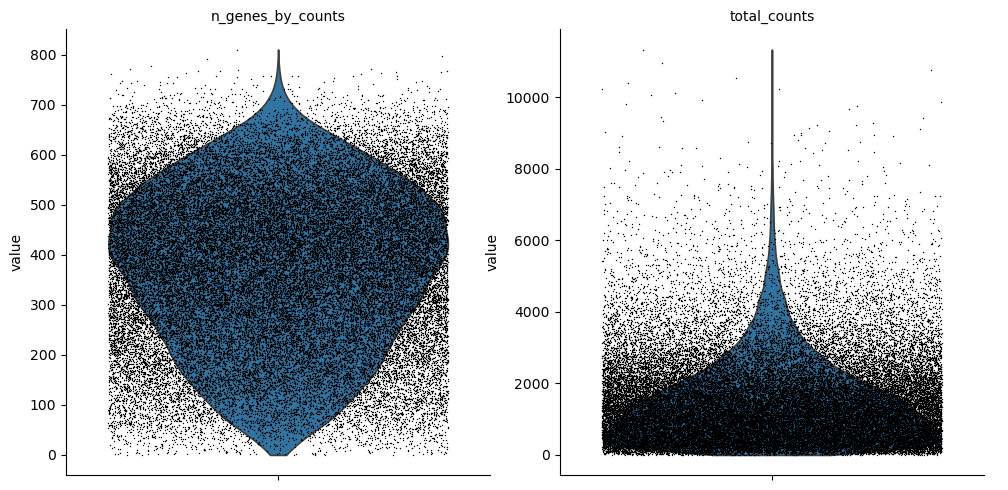

In [199]:
sc.pl.violin(
    sdata_half.tables["gexp"],
    ["n_genes_by_counts", "total_counts"],
    jitter=0.4,
    multi_panel=True,
)

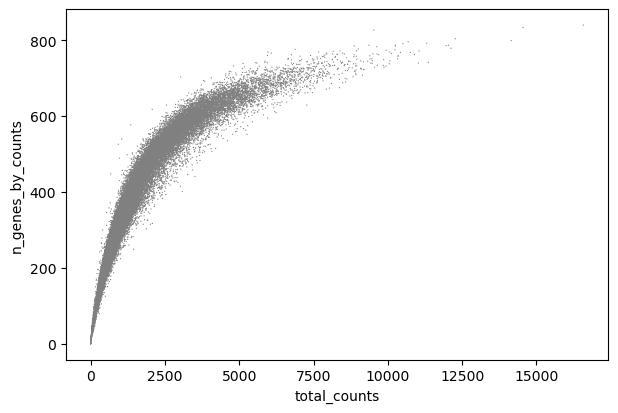

In [200]:
sc.pl.scatter(sdata_quarter.tables["gexp"], "total_counts", "n_genes_by_counts")

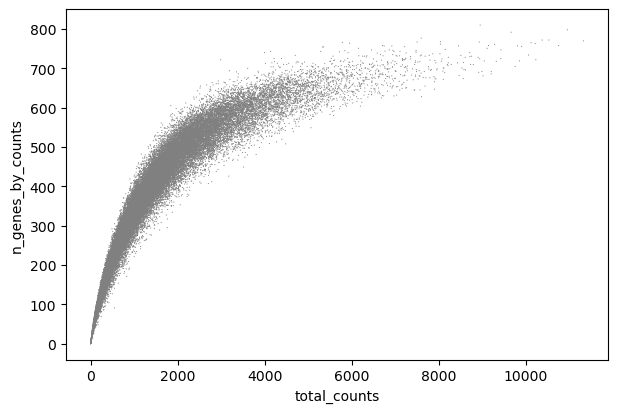

In [201]:
sc.pl.scatter(sdata_half.tables["gexp"], "total_counts", "n_genes_by_counts")

In [202]:
sc.pp.filter_cells(sdata_quarter.tables["gexp"], min_genes=50) # only cells with at least 20 genes expressed
sc.pp.filter_genes(sdata_quarter.tables["gexp"], min_cells=3) # only genes expressed in at least 3 cells

In [203]:
sc.pp.filter_cells(sdata_half.tables["gexp"], min_genes=50) # only cells with at least 20 genes expressed
sc.pp.filter_genes(sdata_half.tables["gexp"], min_cells=3) # only genes expressed in at least 3 cells

In [204]:
sdata_quarter.tables["gexp"].layers["counts"] = sdata_quarter.tables["gexp"].X.copy()
sc.pp.normalize_total(sdata_quarter.tables["gexp"])
sc.pp.log1p(sdata_quarter.tables["gexp"])

In [205]:
sdata_half.tables["gexp"].layers["counts"] = sdata_half.tables["gexp"].X.copy()
sc.pp.normalize_total(sdata_half.tables["gexp"])
sc.pp.log1p(sdata_half.tables["gexp"])

### Now concat for HVG selection

In [206]:
adata_both = ad.concat([sdata_half.tables["gexp"], sdata_quarter.tables["gexp"]])

/ictstr01/home/icb/tim.treis/miniconda/envs/cpmeasure_icml/lib/python3.11/site-packages/anndata/_core/anndata.py:1756: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


In [207]:
sc.pp.highly_variable_genes(adata_both, flavor="seurat", batch_key="tissue")
adata_both_hvgs = adata_both[:, adata_both.var["highly_variable"]].copy()
adata_both_hvgs

/ictstr01/home/icb/tim.treis/miniconda/envs/cpmeasure_icml/lib/python3.11/site-packages/anndata/_core/anndata.py:1756: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


AnnData object with n_obs × n_vars = 86349 × 182
    obs: 'fov_x', 'cellID', 'global_cell_id', 'x_global_px', 'y_global_px', 'x_local_px', 'y_local_px', 'region', 'cell_barcode', 'cluster', 'cluster_long', 'tissue', 'run_tissue', 'fov_y', 'x_fov_px', 'y_fov_px', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'log1p_total_counts_ribo', 'pct_counts_ribo', 'total_counts_hb', 'log1p_total_counts_hb', 'pct_counts_hb', 'n_genes'
    var: 'highly_variable', 'means', 'dispersions', 'dispersions_norm', 'highly_variable_nbatches', 'highly_variable_intersection'
    uns: 'hvg'
    obsm: 'spatial'
    layers: 'counts'

### Integrate

In [208]:
sc.tl.pca(adata_both_hvgs)
sce.pp.harmony_integrate(adata_both_hvgs, key="tissue")

2025-05-16 01:40:12,656 - harmonypy - INFO - Computing initial centroids with sklearn.KMeans...
2025-05-16 01:40:21,565 - harmonypy - INFO - sklearn.KMeans initialization complete.
2025-05-16 01:40:21,939 - harmonypy - INFO - Iteration 1 of 10
2025-05-16 01:40:44,577 - harmonypy - INFO - Iteration 2 of 10
2025-05-16 01:41:06,833 - harmonypy - INFO - Iteration 3 of 10
2025-05-16 01:41:28,643 - harmonypy - INFO - Iteration 4 of 10
2025-05-16 01:41:50,243 - harmonypy - INFO - Iteration 5 of 10
2025-05-16 01:42:04,964 - harmonypy - INFO - Iteration 6 of 10
2025-05-16 01:42:12,061 - harmonypy - INFO - Iteration 7 of 10
2025-05-16 01:42:18,615 - harmonypy - INFO - Iteration 8 of 10
2025-05-16 01:42:25,444 - harmonypy - INFO - Iteration 9 of 10
2025-05-16 01:42:32,222 - harmonypy - INFO - Converged after 9 iterations


In [209]:
fine2coarse = {
    "Astrocytes_Cortex_Hippocampus":         "Astrocytes",
    "Astrocytes_Thalamus_Hypothalamus":      "Astrocytes",
    "Cck_interneurons":                      "Inhibitory neurons",
    "Cholinergic_neurons_Habenula":          "Cholinergic neurons",
    "Choroid_plexus_epithelial_cells":       "Epithelial cells",
    "Commited_oligodendrocytes":             "Oligodendrocytes",
    "D1_medium_spiny_neurons":               "Medium spiny neurons",
    "D2_medium_spiny_neurons":               "Medium spiny neurons",
    "Ependymal_cells":                       "Ependymal cells",
    "Excitatory_neurons_Amygdala":           "Excitatory neurons (Amygdala)",
    "Excitatory_neurons_Di/mesencephalon":   "Excitatory neurons (Di/mesencephalon)",
    "Excitatory_neurons_Hippocampal_CA1":    "Excitatory neurons (Hippocampal_CA1)",
    "Excitatory_neurons_Hippocampal_CA2":    "Excitatory neurons (Hippocampal_CA2)",
    "Excitatory_neurons_Hippocampal_CA3":    "Excitatory neurons (Hippocampal_CA3)",
    "Excitatory_neurons_Layer1_Piriform":    "Excitatory neurons (Layer1_Piriform)",
    "Excitatory_neurons_Layer2_3":           "Excitatory neurons (Layer2_3)",
    "Excitatory_neurons_Layer4":             "Excitatory neurons (Layer4)",
    "Excitatory_neurons_Layer5":             "Excitatory neurons (Layer5)",
    "Excitatory_neurons_Layer5_6":           "Excitatory neurons (Layer5_6)",
    "Excitatory_neurons_Layer6":             "Excitatory neurons (Layer6)",
    "Excitatory_neurons_Telencephalon":      "Excitatory neurons (Telencephalon)",
    "Granule_neurons":                       "Granule neurons",
    "Inhibitory_interneurons":               "Inhibitory neurons",
    "Inhibitory_neurons_Amygdala":           "Inhibitory neurons",
    "Inhibitory_neurons_Habenula_Hypothalamus": "Inhibitory neurons",
    "Inhibitory_neurons_Habenula_Thalamus":  "Inhibitory neurons",
    "Inhibitory_neurons_Reticular_nucleus":  "Inhibitory neurons",
    "Interneurons":                          "Inhibitory neurons",
    "Mature_oligodendrocytes":               "Oligodendrocytes",
    "Microglia":                             "Microglia",
    "Myelin_forming_oligodendrocytes":       "Oligodendrocytes",
    "Neuroblasts":                           "Neuroblasts",
    "Neurogliaform_cells":                   "Inhibitory neurons",
    "Newly_formed_oligodendrocytes":         "Oligodendrocytes",
    "Oligodendrocytes_precursor_cells":      "Oligodendrocytes",
    "Peptidergic_neurons":                   "Peptidergic neurons",
    "Pericytes":                             "Pericytes",
    "Perivascular_macrophages":              "Perivascular macrophages",
    "Serotonergic_neurons":                  "Serotonergic neurons",
    "Tanycytes":                             "Ependymal cells",
    "Telencephalon_inhibitory_neurons":      "Inhibitory neurons",
    "Vascular_endothelial_cells":            "Vascular cells",
    "Vascular_leptomeningeal_cells":         "Vascular cells",
    "Vascular_smooth_muscle_cells":          "Vascular cells"
}

adata_both_hvgs.obs["coarse_cell_type"] = (
    adata_both_hvgs.obs["cluster_long"]
    .map(fine2coarse)
    .fillna("Other")
)

In [210]:
sc.pp.neighbors(adata_both_hvgs, use_rep="X_pca_harmony")
sc.tl.umap(adata_both_hvgs)

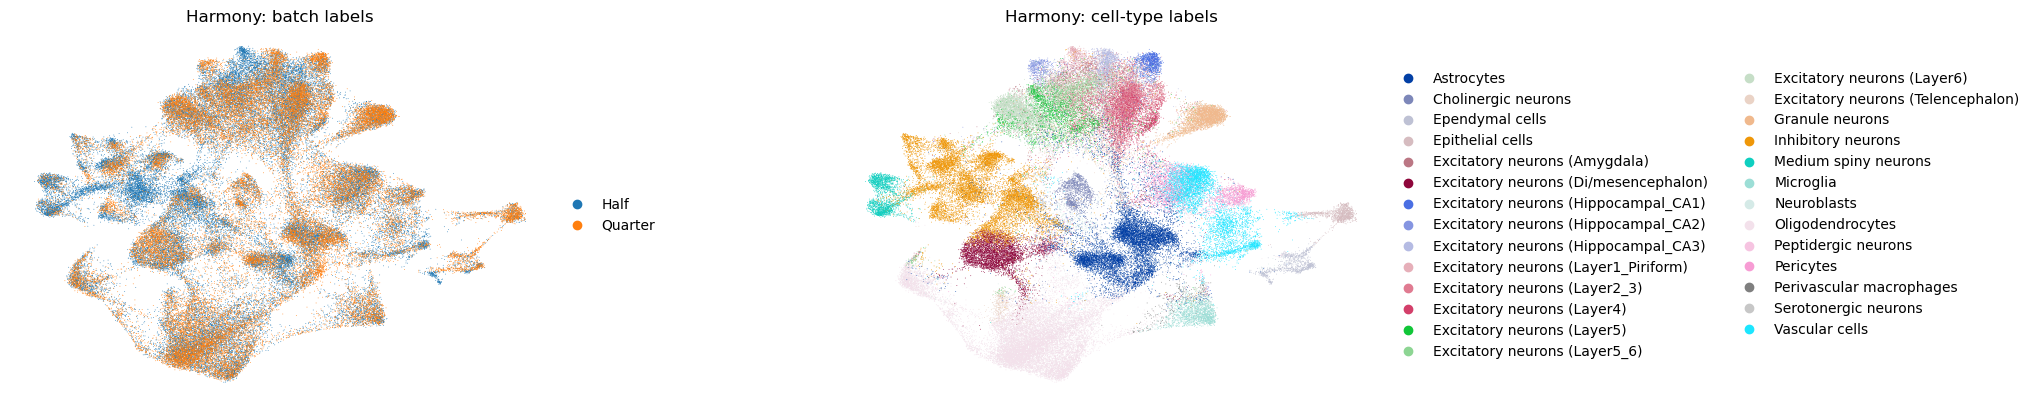

In [211]:
sc.pl.umap(
    adata_both_hvgs,
    color=["tissue", "coarse_cell_type"],
    wspace=0.4,
    title=["Harmony: batch labels", "Harmony: cell‐type labels"],
    frameon=False,
)

### Train classifier

In [212]:
adata_both_hvgs[adata_both_hvgs.obs["tissue"] == "Quarter"].to_df()


,Slc6a1,Aldoc,Id1,Adrb2,Col3a1,Calb2,Fabp7,Hexb,Slc17a7,P2ry14,...,Tgfb1,Fn1,Tgfbr1,S100a16,Fa2h,Nos1,Cck,Aqp4,NegPrb6,NegPrb9
0,0.000000,2.385936,0.000000,0.0,0.000000,0.0,0.000000,0.000000,1.780802,0.000000,...,0.0,0.0,0.000000,0.000000,0.000000,0.000000,2.385936,0.000000,0.0,0.0
1,0.000000,0.000000,0.000000,0.0,0.000000,0.0,0.000000,0.000000,2.812191,0.000000,...,0.0,0.0,0.000000,0.000000,0.000000,0.000000,3.474841,0.000000,0.0,0.0
2,0.000000,0.000000,0.000000,0.0,0.000000,0.0,0.000000,0.835162,1.592407,0.000000,...,0.0,0.0,0.000000,0.000000,0.000000,0.000000,1.827891,0.000000,0.0,0.0
3,1.934638,1.934638,0.000000,0.0,0.000000,0.0,0.000000,0.000000,0.000000,0.000000,...,0.0,0.0,0.000000,0.000000,0.000000,0.686587,2.552805,0.000000,0.0,0.0
4,0.000000,1.180141,0.000000,0.0,0.000000,0.0,0.000000,0.560536,2.141960,0.560536,...,0.0,0.0,0.000000,0.000000,0.560536,0.000000,2.226537,0.000000,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
38989,1.141426,3.558192,2.000627,0.0,1.141426,0.0,1.141426,1.141426,0.000000,2.455834,...,0.0,0.0,0.000000,1.660598,0.000000,0.000000,0.000000,1.660598,0.0,0.0
38990,0.000000,2.031404,0.000000,0.0,0.000000,0.0,0.000000,0.000000,0.000000,0.000000,...,0.0,0.0,1.165729,0.000000,1.165729,0.000000,0.000000,0.000000,0.0,0.0
38991,0.989683,2.049179,0.000000,0.0,0.000000,0.0,0.000000,0.000000,0.000000,0.000000,...,0.0,0.0,0.000000,2.049179,1.803547,0.000000,0.000000,0.000000,0.0,0.0
38993,0.000000,0.000000,0.000000,0.0,0.000000,0.0,0.000000,0.000000,0.000000,0.000000,...,0.0,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.0


In [213]:
adata_both_hvgs[adata_both_hvgs.obs["tissue"] == "Half"]

X_train = adata_both_hvgs[adata_both_hvgs.obs["tissue"] == "Half"].to_df()
y_train_raw = adata_both_hvgs[adata_both_hvgs.obs["tissue"] == "Half"].obs["coarse_cell_type"].values
X_test = adata_both_hvgs[adata_both_hvgs.obs["tissue"] == "Quarter"].to_df()
y_test_raw = adata_both_hvgs[adata_both_hvgs.obs["tissue"] == "Quarter"].obs["coarse_cell_type"].values

# Optional: split training data for validation
label_encoder = LabelEncoder()
y_train = label_encoder.fit_transform(y_train_raw)
y_test = label_encoder.transform(y_test_raw)

# Optional: split training data for validation
X_train_sub, X_val, y_train_sub, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.1,
    random_state=42,
    stratify=y_train
)

# Initialize XGBoost classifier
model = XGBClassifier(
    objective="multi:softprob",       # multiclass classification
    eval_metric="mlogloss",           # evaluation metric
    n_estimators=100,                 # number of boosting rounds
    max_depth=6,                      # maximum tree depth
    learning_rate=0.1,                # learning rate
    random_state=42
)

# Train the model with early feedback on validation set
model.fit(
    X_train_sub,
    y_train_sub,
    eval_set=[(X_val, y_val)],
    verbose=True
)

[0]	validation_0-mlogloss:2.46296
[1]	validation_0-mlogloss:2.15344
[2]	validation_0-mlogloss:1.93841
[3]	validation_0-mlogloss:1.77061
[4]	validation_0-mlogloss:1.63340
[5]	validation_0-mlogloss:1.51740
[6]	validation_0-mlogloss:1.41859
[7]	validation_0-mlogloss:1.33319
[8]	validation_0-mlogloss:1.25850
[9]	validation_0-mlogloss:1.19175
[10]	validation_0-mlogloss:1.13248
[11]	validation_0-mlogloss:1.07899
[12]	validation_0-mlogloss:1.03034
[13]	validation_0-mlogloss:0.98581
[14]	validation_0-mlogloss:0.94559
[15]	validation_0-mlogloss:0.90869
[16]	validation_0-mlogloss:0.87558
[17]	validation_0-mlogloss:0.84538
[18]	validation_0-mlogloss:0.81656
[19]	validation_0-mlogloss:0.79070
[20]	validation_0-mlogloss:0.76684
[21]	validation_0-mlogloss:0.74451
[22]	validation_0-mlogloss:0.72412
[23]	validation_0-mlogloss:0.70553
[24]	validation_0-mlogloss:0.68813
[25]	validation_0-mlogloss:0.67255
[26]	validation_0-mlogloss:0.65737
[27]	validation_0-mlogloss:0.64355
[28]	validation_0-mlogloss:0.6

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=False, eval_metric='mlogloss',
              feature_types=None, feature_weights=None, gamma=None,
              grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=0.1, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=6, max_leaves=None,
              min_child_weight=None, missing=nan, monotone_constraints=None,
              multi_strategy=None, n_estimators=100, n_jobs=None,
              num_parallel_tree=None, ...)

In [214]:
seen = np.unique(y_test)
seen_names = [str(label_encoder.classes_[i]) for i in seen]
y_pred = model.predict(X_test)

gexp_report = classification_report(
    y_test,
    y_pred,
    labels=seen,
    target_names=seen_names,
    output_dict=True,
    zero_division=0
)
gexp_report_df = pd.DataFrame(gexp_report).T
gexp_report_df

,precision,recall,f1-score,support
Astrocytes,0.908775,0.866611,0.887193,4828.000000
Cholinergic neurons,0.967018,0.939744,0.953186,780.000000
Ependymal cells,0.960076,0.866209,0.910730,583.000000
Epithelial cells,0.961929,0.980595,0.971172,773.000000
Excitatory neurons (Amygdala),0.077720,0.234375,0.116732,64.000000
Excitatory neurons (Di/mesencephalon),0.811601,0.965241,0.881778,1870.000000
Excitatory neurons (Hippocampal_CA1),0.957037,0.847769,0.899095,762.000000
Excitatory neurons (Hippocampal_CA2),0.969697,0.717087,0.824477,357.000000
Excitatory neurons (Hippocampal_CA3),0.946903,0.674653,0.787923,793.000000
Excitatory neurons (Layer1_Piriform),0.061497,0.450980,0.108235,51.000000


<Axes: >

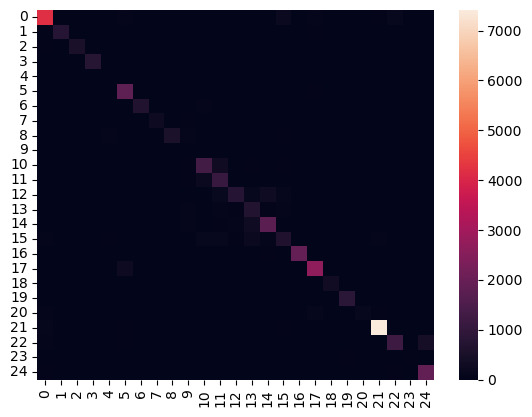

In [223]:
sns.heatmap(confusion_matrix(y_test, y_pred))

In [225]:
celltypes = [r for r in gexp_report_df.index if r not in ("accuracy", "micro avg", "macro avg", "weighted avg")]
f1_scores = gexp_report_df.loc[celltypes, "f1-score"].tolist()

# --- 2) grab your hex‐color dict from adata ---
cats    = adata_both_hvgs.obs["coarse_cell_type"].cat.categories.tolist()
hexes   = adata_both_hvgs.uns["coarse_cell_type_colors"]
color_dict = dict(zip(cats, hexes))

In [226]:
sdata_half.tables["gexp"].obs["coarse_cell_type"] = pd.Categorical(adata_both_hvgs.obs.query("tissue == 'Half'")["coarse_cell_type"])

In [227]:
def plot_f1_violin(ax):
    """
    On the passed‐in Axes `ax`, draws:
      – grey violins for two scenarios (“Gene Expression” vs “Gene + Morphology”)
      – colored connector‐lines per cell‐type
      – hollow circles per cell‐type, colored by your adata palette.
    Assumes the following are defined in the global scope:
      celltypes, f1_expr, f1_expr_morph, adata_both_hvgs
    """
    # --- 1) build the long DataFrame ---
    df = pd.DataFrame({
        "CellType":   celltypes * 2,
        "F1":          f1_scores + f1_scores,
        "Scenario":   ["Gene Expression"] * len(celltypes)
                     + ["Gene + Morphology"] * len(celltypes)
    })

    # --- 3) the grey violins ---
    # sns.violinplot(
    #     x="Scenario", y="F1", data=df,
    #     inner=None,            # no quartiles
    #     color="lightgrey",
    #     ax=ax
    #)

    # --- 4) colored connector lines ---
    for ct in celltypes:
        y0 = df.loc[(df.CellType==ct)&(df.Scenario=="Gene Expression"),    "F1"].item()
        y1 = df.loc[(df.CellType==ct)&(df.Scenario=="Gene + Morphology"), "F1"].item()
        ax.plot([0,1], [y0,y1],
                color=color_dict[ct],
                alpha=0.7,
                linewidth=3)

    # --- 5) hollow circles, colored by cell‐type ---
    sns.stripplot(
        x="Scenario", y="F1", data=df,
        hue="CellType",
        palette=color_dict,
        size=12,
        jitter=False,
        edgecolor="black",
        linewidth=0,
        ax=ax
    )
    ax.get_legend().remove()   # we’ll build the legend elsewhere
    ax.set_ylabel("F1 Score")

    # for spine in ["top", "right", "bottom"]:
    #     ax.spines[spine].set_visible(False)

    # remove the x‐axis ticks and label
    ax.set_xticks([])
    ax.set_xlabel("")

    return ax


In [219]:
from matplotlib.lines import Line2D

def create_celltype_legend(ax, color_dict, ncol=2, title="Cell Types"):
    """
    On the passed‐in Axes `ax`, draws a legend of cell‐type circles.
    
    Parameters
    ----------
    ax : matplotlib.axes.Axes
        The axes to draw the legend into.
    color_dict : dict
        Mapping from cell‐type name to hex color.
    ncol : int, optional
        Number of columns in the legend. Default is 2.
    title : str, optional
        Legend title. Default is "Cell Types".
    """
    # build one Line2D per cell‐type, with circular markers
    handles = [
        Line2D(
            [0], [0],
            marker="o",
            color="none",
            markerfacecolor=color,
            markeredgecolor="black",
            markersize=8,
            label=ct
        )
        for ct, color in color_dict.items()
    ]
    ax.legend(
        handles=handles,
        title=title,
        loc="center",
        ncol=ncol,
        frameon=False
    )
    ax.axis("off")
    return ax

In [220]:
del sdata_half.tables["gexp"].uns["coarse_cell_type_colors"]

KeyError: 'coarse_cell_type_colors'

In [221]:
crop = sdata_half.query.bounding_box(
    axes=["x", "y"],
    min_coordinate=[10450, 10300],
    max_coordinate=[10850, 10700],
    target_coordinate_system="global",
)

/ictstr01/home/icb/tim.treis/miniconda/envs/cpmeasure_icml/lib/python3.11/functools.py:909: UserWarning: The object has `points` element. Depending on the number of points, querying MAY suffer from performance issues. Please consider filtering the object before calling this function by calling the `subset()` method of `SpatialData`.
  return dispatch(args[0].__class__)(*args, **kw)


/ictstr01/home/icb/tim.treis/miniconda/envs/cpmeasure_icml/lib/python3.11/site-packages/spatialdata_plot/pl/utils.py:798: FutureWarning: The default value of 'ignore' for the `na_action` parameter in pandas.Categorical.map is deprecated and will be changed to 'None' in a future version. Please set na_action to the desired value to avoid seeing this warning
  color_vector = color_source_vector.map(color_mapping)


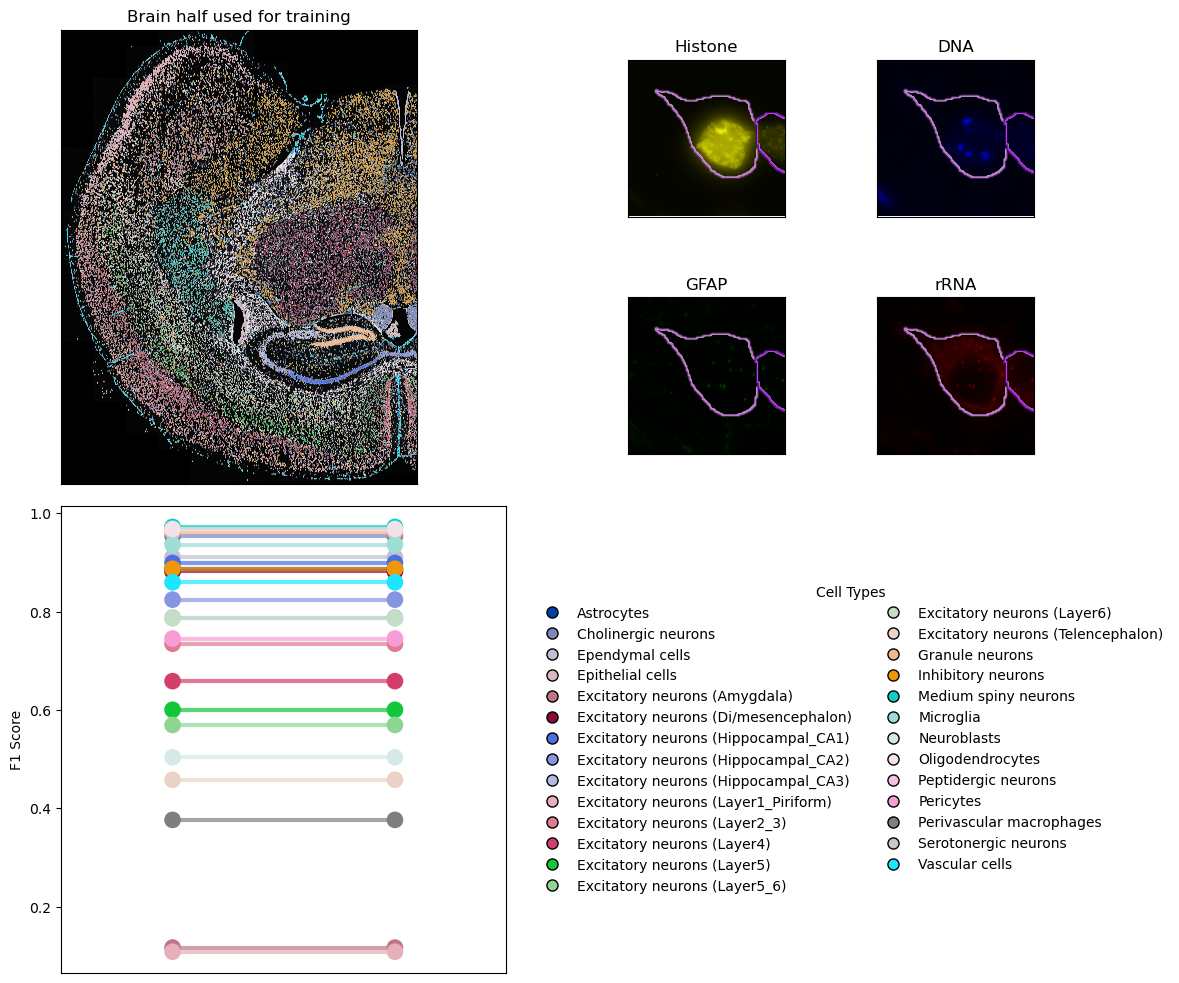

In [228]:
from matplotlib.gridspec import GridSpec

fig = plt.figure(figsize=(12,10))

# 1) Make an “outer” 2×2 GridSpec
outer_gs = GridSpec(2, 2, figure=fig)

# ── Top-Left: Brain ────────────────────────────────────────────
ax_brain = fig.add_subplot(outer_gs[0, 0])
(
    sdata_half
    .pl.render_images(channel="DNA", scale="scale2", cmap="gray")
    .pl.render_labels(scale="scale2", color="coarse_cell_type", fill_alpha=1)
    .pl.show(ax=ax_brain, title="Brain half used for training")
)

ax_brain.set_xticks([])
ax_brain.set_yticks([])
# clear any axis labels/titles
ax_brain.set_xlabel("")
ax_brain.set_ylabel("")

# remove the Scanpy legend on that axis
leg = ax_brain.get_legend()
if leg:
    leg.remove()

# ── Bottom-Left: Violin + Lines ────────────────────────────────
ax_violin = fig.add_subplot(outer_gs[1, 0])
plot_f1_violin(ax_violin)

# ── Top-Right: subdivide into 2×2 ──────────────────────────────
inner_gs = outer_gs[0, 1].subgridspec(2, 2)

ax00 = fig.add_subplot(inner_gs[0, 0])
ax01 = fig.add_subplot(inner_gs[0, 1])
ax10 = fig.add_subplot(inner_gs[1, 0])
ax11 = fig.add_subplot(inner_gs[1, 1])

(
    crop
    .pl.render_images(channel="Histone", scale="scale0", palette="yellow")
    .pl.render_labels(fill_alpha=0, outline_alpha=1, contour_px=10)
    .pl.show(ax=ax00, title="Histone")
)

(
    crop
    .pl.render_images(channel="DNA", scale="scale0", palette="blue")
    .pl.render_labels(fill_alpha=0, outline_alpha=1, contour_px=10)
    .pl.show(ax=ax01, title="DNA")
)

(
    crop
    .pl.render_images(channel="GFAP", scale="scale0", palette="green")
    .pl.render_labels(fill_alpha=0, outline_alpha=1, contour_px=10)
    .pl.show(ax=ax10, title="GFAP")
)

(
    crop
    .pl.render_images(channel="rRNA", scale="scale0", palette="red")
    .pl.render_labels(fill_alpha=0, outline_alpha=1, contour_px=10)
    .pl.show(ax=ax11, title="rRNA")
)

for ax in (ax00, ax01, ax10, ax11):
    # completely remove tick marks
    ax.set_xticks([])
    ax.set_yticks([])
    # clear any axis labels/titles
    ax.set_xlabel("")
    ax.set_ylabel("")

# put your circle-legend in the upper-left of that block
ax_legend = fig.add_subplot(outer_gs[1, 1])
create_celltype_legend(ax_legend, color_dict, ncol=2)

# turn the other three small panels off
# for ax in (ax01, ax10, ax11):
#     ax.axis("off")

# ── Bottom-Right: unused ───────────────────────────────────────
# ax_blank.axis("off")

# ── Finally: delete ANY extra colorbar axes Scanpy snuck in ─────
keep = {ax_brain, ax_violin, ax_legend, ax00, ax01, ax10, ax11}
for ax in fig.axes[:]:
    if ax not in keep:
        fig.delaxes(ax)

plt.tight_layout()
plt.show()


In [ ]:
crop

SpatialData object
├── Images
│     └── 'stitched_image': DataTree[cyx] (5, 400, 400), (5, 200, 200), (5, 100, 100), (5, 50, 50), (5, 25, 25)
├── Labels
│     └── 'segmentation': DataTree[yx] (400, 400), (200, 200), (100, 100), (50, 50), (25, 25)
├── Points
│     └── 'points': DataFrame with shape: (<Delayed>, 12) (3D points)
└── Tables
      └── 'gexp': AnnData (3, 960)
with coordinate systems:
    ▸ 'global', with elements:
        stitched_image (Images), segmentation (Labels), points (Points)

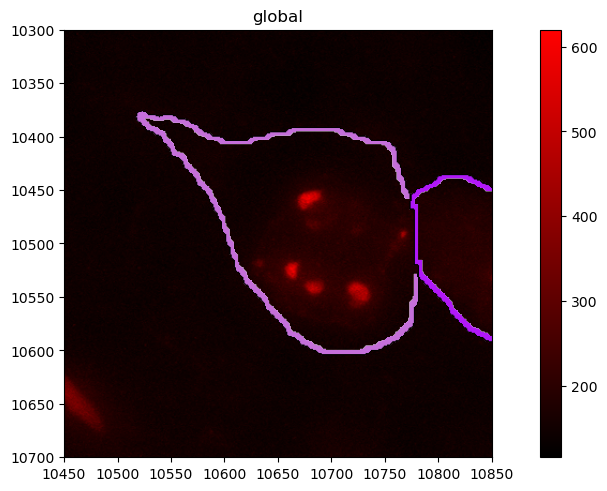

In [ ]:
(
    crop
    .pl.render_images(channel="DNA", scale="scale0", palette="red")
    .pl.render_labels(fill_alpha=0, outline_alpha=1, contour_px=10)
    .pl.show()
)
#ValueError: Invalid channel(s): DNA2. Valid choices are: ['Histone' 'DNA' 'GFAP' 'G' 'rRNA']